# Esperimento frange di intensità luminosa di interferenza e diffrazione

#### Importiamo le librerie necessarie e definiamo le costanti

In [319]:
import matplotlib.pyplot as plt
import math
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import chi2
import pandas as pd

In [303]:
B = 20
I0=400
alfa = 0.9
delta = 5.20
rng=np.random.default_rng(3297894501)

##### Definiamo le funzioni del modello dividendo la funzione mu in due sottofunzioni e calcoliamo l'inviluppo

In [304]:
x = np.linspace(-5.0, 5.0, 161)

def E(array1, alfa):
    return np.sinc(alfa*array1/np.pi)**2

def C(array2, delta):
    return (np.cos(delta*array2))**2

def Mu(array1, B, I0, alfa, delta):
    return B+I0*E(array1, alfa)*C(array1, delta)

inviluppo=B+I0*E(x, alfa)

##### Controlliamo che il modello si comporti coerentemente con le aspettative fisiche

In [305]:
if np.all(Mu(x, B, I0, alfa, delta)>=0) and np.all(np.isfinite(Mu(x, B, I0, alfa, delta))) and np.all(Mu(x, B, I0, alfa, delta)==Mu(-x, B, I0, alfa, delta)) and Mu(0, B, I0, alfa, delta)==B+I0:
    print(True)

True


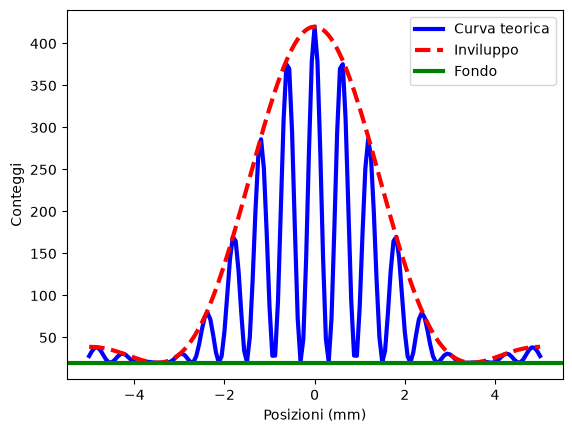

In [306]:
grafico, asse =plt.subplots()
asse.plot(x,Mu(x, B, I0, alfa, delta), "b-", lw=3, label="Curva teorica")
asse.plot(x,inviluppo, "r--", lw=3, label="Inviluppo")
asse.axhline(B, color="g", lw=3, label="Fondo")
asse.set(xlabel="Posizioni (mm)", ylabel="Conteggi")
asse.legend()

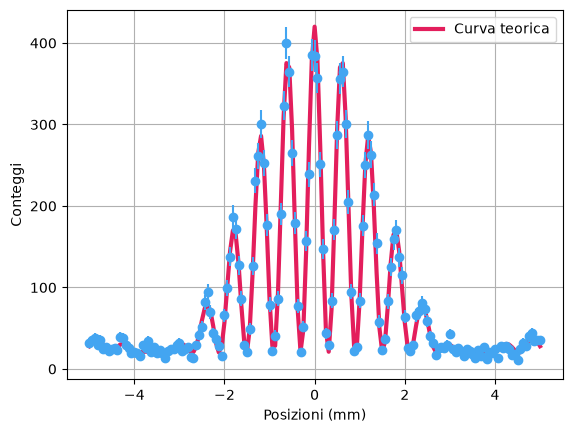

In [307]:
n=rng.poisson(Mu(x, B, I0, alfa, delta))
errori=[]
for ni in n:
    if ni==0:
        errori.append(1)
    else:
        errori.append(ni**0.5)
errors=np.array(errori)
grafico, asse =plt.subplots()
asse.plot(x,Mu(x, B, I0, alfa, delta), "-",color="#e31e5c", lw=3, label="Curva teorica")
#asse.plot(x,inviluppo, "r--", lw=3, label="Inviluppo")
#asse.axhline(B, color="g", lw=3, label="Fondo")
asse.errorbar(x,n,yerr=errors, fmt='o', color="#43a5f1")
asse.set(xlabel="Posizioni (mm)", ylabel="Conteggi")
asse.grid()
asse.legend()

In [308]:
Nc=np.sum(n[abs(x) < 1.2])
mu_c=np.sum(Mu(x[abs(x) < 1.2], B, I0, alfa, delta))
statistica=(Nc-mu_c)/(mu_c**0.5)
print(statistica)

-1.3195955178021102


In [309]:
m=30000
def generatore(array):
    ni=rng.poisson(Mu(array, B, I0, alfa, delta))
    Nc_i=np.sum(ni[abs(array) < 1.2])
    return Nc_i

risultati_=[]
for i in range(m):
    risultati_.append(generatore(x))
risultati=np.array(risultati_)
media=risultati.mean()
dev_std=risultati.std(ddof=1)
dev_std_med=dev_std/(m**0.5)
scarto_rel=media-mu_c
rapporto_deviazioni=dev_std/(mu_c**0.5)

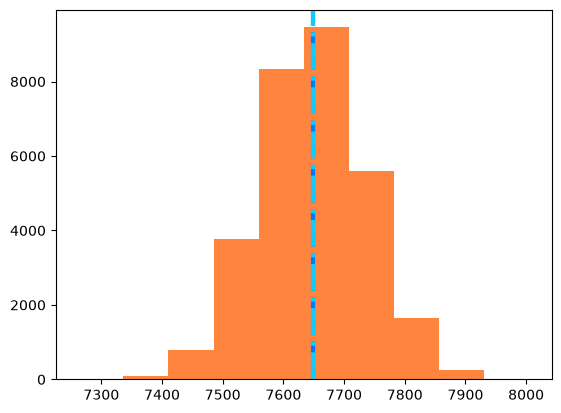

In [310]:
figura1, assi =plt.subplots()
assi.hist(risultati, color="#FF853F")
assi.axvline(media, color="#007BFF", lw=3, linestyle="--")
assi.axvline(mu_c, color="#10cBFb", lw=3, linestyle="-.")

In [311]:
y= np.array(Mu(x, B, I0, alfa, delta))
df = pd.DataFrame({"x": x, "y" : n, "sigma_y": errors})
df.to_csv("dati_fit.csv", index = False)
dati = np.genfromtxt("dati_fit.csv", delimiter = ",", names = True)
x = dati["x"]
n = dati["y"]
errors = dati["sigma_y"]

/tmp/ipykernel_8659/3415474825.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  asse.legend()


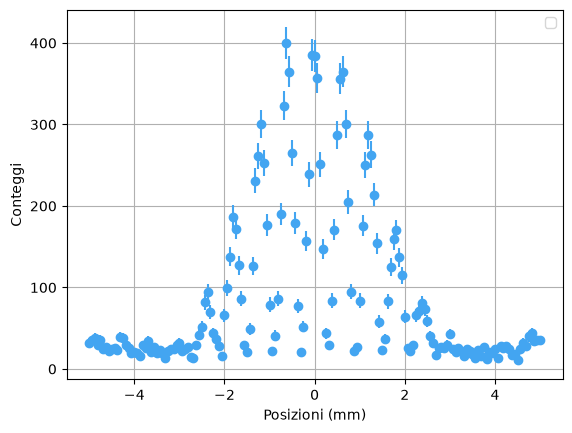

In [312]:
grafico, asse =plt.subplots()
asse.errorbar(x ,n,yerr=errors, fmt='o', color="#43a5f1")
asse.set(xlabel="Posizioni (mm)", ylabel="Conteggi")
asse.grid()
asse.legend()

In [313]:
y_esterni = Mu(x[abs(x > 1.2)], B, I0, alfa, delta)
B0_iniziale = np.median(y_esterni)
I0_iniziale = np.max(y) - B0_iniziale
alfa_iniziale = np.pi/3.2
#alfa_iniziale = 0.9     #true
delta_iniziale = np.pi/0.6
#delta_iniziale = 5.2    #true
Parametri_iniziali = (B0_iniziale, I0_iniziale, alfa_iniziale, delta_iniziale)
p0 = np.array (Parametri_iniziali)
lower = [0.0, 0.0, 0.10, 1.0]
upper = [np.inf, np.inf, 3.0, 12.0]
parametri = ["B", "I0", "alfa", "delta"]
for i in range(len(p0)):
    print(parametri[i] , p0[i])


B 27.8994254236928
I0 392.1005745763072
alfa 0.9817477042468103
delta 5.235987755982989


In [314]:
popt, pcov = curve_fit (
    Mu, x, n, 
    p0 = p0,
    sigma = errors,
    absolute_sigma = True,
    bounds = (lower, upper),
    maxfev = 100000
)
parametri_errori = np.sqrt(np.diag(pcov))
for i in range(len(popt)):
    print(popt[i], parametri_errori[i])

19.300967410645157 0.5019343147436705
395.3784943310357 4.939758864368743
0.8883673198972886 0.006684078707184713
5.195486096578722 0.00585229467121436


matrice di covarianza:
[[ 2.51938056e-01 -6.41899405e-01  4.46315290e-04  7.28111486e-05]
 [-6.41899405e-01  2.44012176e+01  1.41806768e-02 -1.93905076e-04]
 [ 4.46315290e-04  1.41806768e-02  4.46769082e-05  2.06534139e-07]
 [ 7.28111486e-05 -1.93905076e-04  2.06534139e-07  3.42493529e-05]]

matrice di correlazione:
[[ 1.         -0.25888944  0.13303114  0.02478705]
 [-0.25888944  1.          0.42948664 -0.00670745]
 [ 0.13303114  0.42948664  1.          0.00527988]
 [ 0.02478705 -0.00670745  0.00527988  1.        ]]


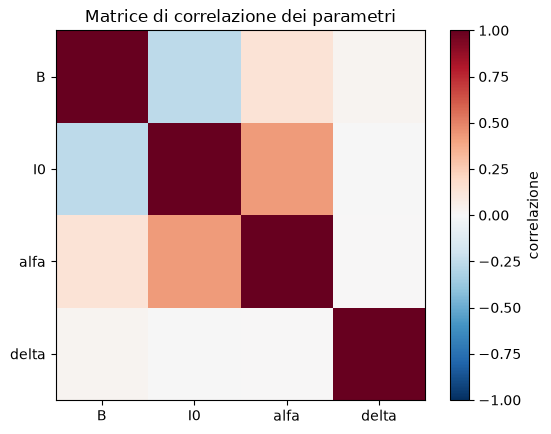

In [315]:
def covarianza_in_correlazione(cov):
    deviazioni = np.sqrt(np.diag(cov))
    return cov / np.outer(deviazioni, deviazioni)

pcorr = covarianza_in_correlazione(pcov)

print("matrice di covarianza:")
print(pcov)
print("\nmatrice di correlazione:")
print(pcorr)

plt.imshow(pcorr, vmin=-1, vmax=1, cmap="RdBu_r")
plt.colorbar(label="correlazione")
plt.xticks([0, 1, 2, 3], ["B", "I0", "alfa", "delta"])
plt.yticks([0, 1, 2, 3], ["B", "I0", "alfa", "delta"])
plt.title("Matrice di correlazione dei parametri")
plt.show()

In [320]:
def residui(array_stime, array_vero):
    residui_ = array_stime - array_vero
    return residui_

def pulls(array_stime, array_vero):
    pulls_ = residui(array_stime, array_vero)/errors
    return pulls_

def chi2_1 (array_stime, array_vero):
    chi2_ = np.sum(pulls(array_stime, array_vero)**2)
    return chi2_

def gdl (array_stime):
    gdl_ = len(array_stime) - 4
    return gdl_

def chi2_ridotto (array_stime, array_vero):
    chi2_ridotto_ = chi2_1(array_stime, array_vero) / gdl(array_stime)
    return chi2_ridotto_

def mu_stimato(array):
    return popt[0]+popt[1]*E(array, popt[2])*C(array, popt[3])

p_value = chi2.sf(chi2_1(n, Mu(x, B, I0, alfa, delta)), gdl(n))
    

print(residui(n, Mu(x, B, I0, alfa, delta)), "\n", pulls(n, Mu(x, B, I0, alfa, delta)), "\n", chi2_1(n, Mu(x, B, I0, alfa, delta)), "\n", gdl(n), "\n", chi2_ridotto(n, Mu(x, B, I0, alfa, delta)), "\n", p_value)

[  4.10057458   1.18549817   0.20523747  -8.15951974   1.19836427
  -4.19610756   3.310212     1.57774501   3.60580077   2.88897758
  -3.93503088   9.06805188   7.2278178   -0.25257213  -0.22632362
  -4.04208745   0.16992592  -1.01455786  -4.26965799   8.12831229
   4.81022545  12.9873774    0.45330267   6.85407753  -1.001807
   2.96986     -1.03359932  -6.0033123    1.70477506   2.52217492
   0.12392015   1.90596244   2.09422228  -8.75307491  -3.72392957
   2.4945563   -5.65609663  -6.77996857   1.24651128   0.21738569
  -7.38929378   7.82079689  14.55632892  -1.63332387  -9.0340541
   4.96858675   7.71271762 -11.63583543   9.15332079  -1.87348281
  -6.4158077   17.22795491   7.17192422  -2.64140777   7.75816079
  -5.10785245   0.39170251  -1.26449926   8.28539945  30.91849093
  -4.38504978  15.03935345   1.76948588   3.05220795  -7.5137085
  -6.22064786  12.53468847  -7.16580469 -10.66000232  13.5036103
  24.65636879  -5.02658183 -29.40596042  -0.17704345   4.23631003
  -0.14343266  

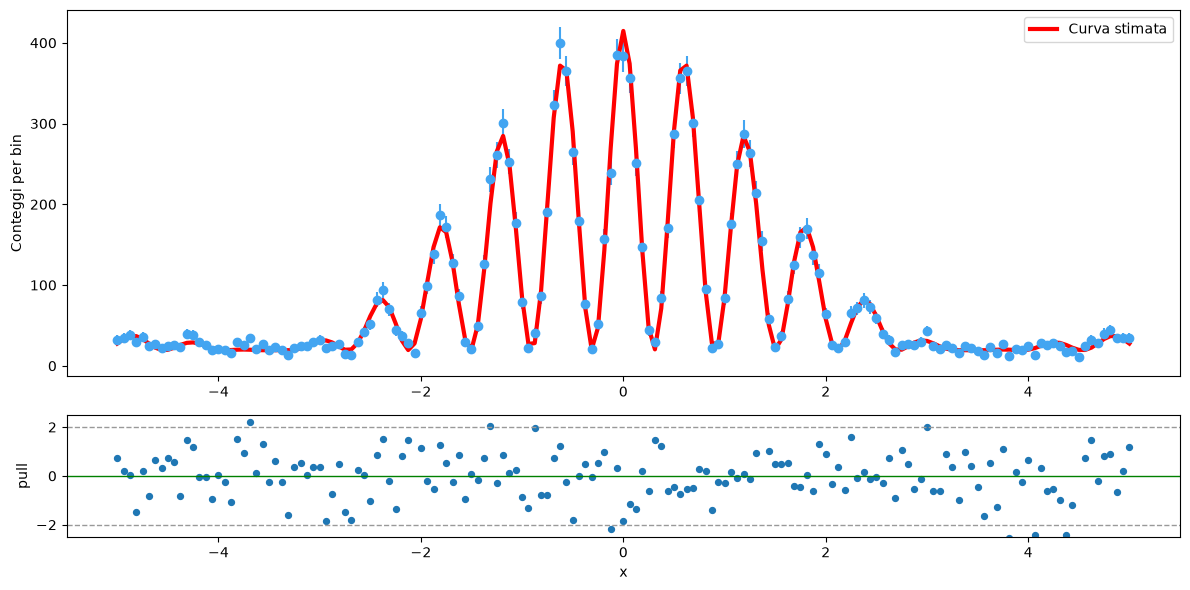

In [317]:
pulls_stima = pulls(n, Mu(x, B, I0, alfa, delta))

fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, figsize=(12, 6),
    gridspec_kw={"height_ratios": [3, 1]}
)
ax_top.errorbar(x, n, yerr=errors, fmt='o', color="#43a5f1")
ax_top.plot(x, mu_stimato(x), 'r-', lw = 3, label = "Curva stimata")
ax_top.set_ylabel("Conteggi per bin")
ax_top.legend()

ax_bottom.axhline(0, color="green", lw=1)
ax_bottom.axhline(2, color="0.6", ls="--", lw=1)
ax_bottom.axhline(-2, color="0.6", ls="--", lw=1)
ax_bottom.scatter(x, pulls_stima, s=18, color="tab:blue")
ax_bottom.set(xlabel="x", ylabel="pull", ylim=(-2.5, 2.5))

plt.tight_layout()
plt.show()
